# DS2 data preprocessing

Prepares DS2 (Kaggle Kidney Disease Dataset, 20,538 patients, 5 risk levels) for the models. Input is the output of `Feature_Engineering.ipynb`, where text features are already encoded and 2 new features are added. Steps: describe the data, split into train and test, explore the training set, check data quality, scale, handle class imbalance, and save the result. Output is `processed/train.csv` and `processed/test.csv`, used by the clustering and model notebooks.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import mutual_info_classif
from sklearn.utils.class_weight import compute_class_weight

RANDOM_STATE = 42

## 1. Load DS2 and describe the data

**About the dataset**

| | |
|---|---|
| Source | [Kaggle, uploaded by amanik000](https://www.kaggle.com/datasets/amanik000/kidney-disease-dataset) |
| License | Not given on Kaggle; the uploader states it is for machine learning and healthcare research (amanik000, n.d.). The first 24 columns come from the UCI CKD dataset, CC BY 4.0 (Rubini et al., 2015) |
| Collection method | Not stated. The UCI part comes from hospital records in India over about 2 months (Rubini et al., 2015); the extra 18 columns and rows are undocumented |
| Size | 20,538 patients, 42 original features plus 2 engineered (46 columns after one-hot encoding), 1 target |
| Target | 5 risk levels: No Disease, Low, Moderate, High, Severe |

**Why this dataset**
- 5 risk levels instead of yes/no, matching objective 1 and clinical risk grouping (KDIGO, 2024)
- eGFR, advanced biomarkers and lifestyle features to test objective 2
- Large enough to train an MLP (objective 3)
- Most CKD studies use the 400-row binary UCI dataset, often with near-perfect accuracy (Rubini et al., 2015; Qin et al., 2020); DS2 is a larger multi-class version
- Already used on Kaggle (Bhagat, n.d.), so results can be compared

In [2]:
path = "../../../../assets/datasets/2_KG_Kidney_Disease_Dataset/data/kidney_disease_dataset_processed.csv"
df = pd.read_csv(path)

labels = ["High_Risk", "Low_Risk", "Moderate_Risk", "No_Disease", "Severe_Disease"]
df["Target"] = df["Target"].map(dict(enumerate(labels)))

overview = pd.Series({
    "Rows": df.shape[0],
    "Columns": df.shape[1],
    "0/1 columns": (df.nunique() == 2).sum(),
    "Other numeric columns": ((df.nunique() > 2) & (df.dtypes != object)).sum(),
    "Missing values": df.isnull().sum().sum(),
    "Duplicate rows": df.duplicated().sum(),
}, name="Value").to_frame()
display(overview)

,Value
Rows,20538
Columns,47
0/1 columns,17
Other numeric columns,29
Missing values,0
Duplicate rows,0


In [3]:
columns = pd.DataFrame({
    "Type": df.dtypes.astype(str),
    "Missing": df.isnull().sum(),
    "Unique": df.nunique(),
    "Values / Range": [
        ", ".join(sorted(map(str, df[c].unique()))) if df[c].dtype == "object"
        else f"{df[c].min():g} to {df[c].max():g}"
        for c in df.columns
    ],
})
display(columns)

,Type,Missing,Unique,Values / Range
Age of the patient,int64,0,86,5 to 90
Blood pressure (mm/Hg),int64,0,101,80 to 180
Specific gravity of urine,float64,0,21,1.005 to 1.025
Albumin in urine,int64,0,6,0 to 5
Sugar in urine,int64,0,6,0 to 5
Red blood cells in urine,int64,0,2,0 to 1
Pus cells in urine,int64,0,2,0 to 1
Pus cell clumps in urine,int64,0,2,0 to 1
Bacteria in urine,int64,0,2,0 to 1
Random blood glucose level (mg/dl),int64,0,431,70 to 500


**Feature groups**

| Group (columns) | Features | Role |
|---|---|---|
| Kidney function (6) | eGFR, serum creatinine, blood urea, Cystatin C, urine protein-to-creatinine ratio, albumin in urine | Main CKD markers (KDIGO, 2024) |
| Blood tests (12) | hemoglobin, packed cell volume, red and white cell counts, sodium, potassium, calcium, phosphate, serum albumin, cholesterol, glucose, PTH | CKD complications such as anemia |
| Urine tests (8) | specific gravity, sugar, red cells, pus cells, pus cell clumps, bacteria, sediment microscopy, urine output | Kidney damage |
| Inflammation (2) | CRP, IL-6 | Advanced biomarkers, not in UCI |
| Medical history (9) | hypertension and diabetes (with years), coronary artery disease, anemia, pedal edema, appetite, family history | Known risk factors |
| Lifestyle and demographics (7) | age, blood pressure, BMI, smoking, physical activity (3 one-hot columns) | Changeable risk factors |
| Engineered (2) | Diabetes x Hypertension, BMI x Age | Added in `Feature_Engineering.ipynb` |

In [4]:
display(df.head())

,Age of the patient,Blood pressure (mm/Hg),Specific gravity of urine,Albumin in urine,Sugar in urine,Red blood cells in urine,Pus cells in urine,Pus cell clumps in urine,Bacteria in urine,Random blood glucose level (mg/dl),...,Cystatin C level,Urinary sediment microscopy results,C-reactive protein (CRP) level,Interleukin-6 (IL-6) level,Target,Physical activity level_high,Physical activity level_low,Physical activity level_moderate,Diabetes_Hypertension_Interaction,BMI_Age_Interaction
0,54,167,1.023,1,4,1,0,0,0,96,...,0.67,1,4.88,10.23,No_Disease,0,1,0,1,1366.2
1,42,127,1.023,3,2,1,1,0,1,73,...,0.55,0,4.49,13.11,Low_Risk,0,0,1,0,865.2
2,38,148,1.016,0,0,0,1,0,0,77,...,2.37,0,4.57,13.27,No_Disease,1,0,0,0,1459.2
3,7,98,1.017,4,0,0,1,0,1,225,...,2.54,0,8.57,12.36,No_Disease,1,0,0,0,172.9
4,67,174,1.015,1,1,1,0,0,0,376,...,1.90,1,6.75,1.46,No_Disease,1,0,0,0,1179.2


**Observation:**
- Loaded from `Feature_Engineering.ipynb`: text features already 0/1, physical activity one-hot, 2 new features
- Its Target labels are alphabetical (0 High Risk to 4 Severe), so they are mapped back to names here

## 2. Stratified train/test split

In [5]:
X = df.drop(columns=["Target"])
y = df["Target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

split = pd.DataFrame({
    "Rows": [len(X_train), len(X_test)],
    "Features": [X_train.shape[1], X_test.shape[1]],
}, index=["Train", "Test"])
display(split)

,Rows,Features
Train,16430,46
Test,4108,46


In [6]:
balance = pd.DataFrame({
    "Train %": y_train.value_counts(normalize=True).mul(100).round(1),
    "Test %": y_test.value_counts(normalize=True).mul(100).round(1),
})
display(balance)

,Train %,Test %
Target,,
High_Risk,4.0,4.0
Low_Risk,10.0,10.0
Moderate_Risk,4.0,4.0
No_Disease,80.0,80.0
Severe_Disease,2.0,2.0


**Observation:**
- Target is imbalanced (80% No Disease, 2% Severe), so the stratified split keeps the same class mix in train and test (Géron, 2022)

## 3. Explore the training set

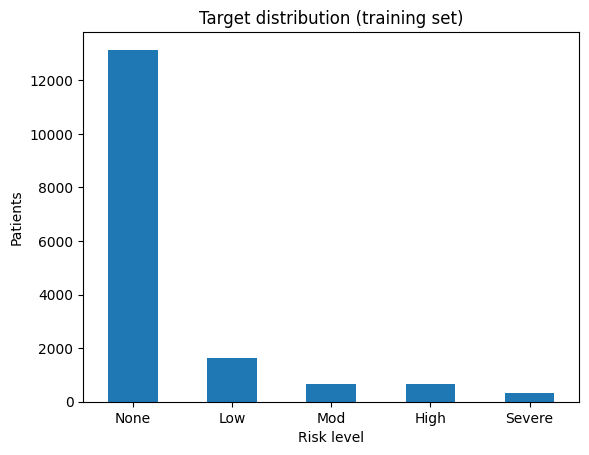

Imbalance ratio: 40.1


In [7]:
train = X_train.copy()
train["Target"] = y_train
order = ["No_Disease", "Low_Risk", "Moderate_Risk", "High_Risk", "Severe_Disease"]
short = ["None", "Low", "Mod", "High", "Severe"]

counts = train["Target"].value_counts().reindex(order)
counts.set_axis(short).plot(kind="bar", title="Target distribution (training set)")
plt.xlabel("Risk level")
plt.ylabel("Patients")
plt.xticks(rotation=0)
plt.show()
print("Imbalance ratio:", round(counts.max() / counts.min(), 1))

In [8]:
num_cols = [c for c in X_train.columns if X_train[c].nunique() > 2]
binary_cols = [c for c in X_train.columns if c not in num_cols]
stats = train[num_cols].describe().T[["min", "max", "mean", "std"]]
stats["skew"] = train[num_cols].skew()
display(stats.round(3))

,min,max,mean,std,skew
Age of the patient,5.000,90.000,47.571,24.888,0.001
Blood pressure (mm/Hg),80.000,180.000,130.224,29.136,-0.016
Specific gravity of urine,1.005,1.025,1.015,0.006,-0.013
Albumin in urine,0.000,5.000,2.490,1.700,0.011
Sugar in urine,0.000,5.000,2.488,1.701,0.005
Random blood glucose level (mg/dl),70.000,500.000,283.647,124.645,0.008
Blood urea (mg/dl),7.002,199.994,104.159,55.794,-0.017
Serum creatinine (mg/dl),0.500,15.000,7.768,4.174,0.000
Sodium level (mEq/L),120.001,150.000,135.088,8.647,-0.014
Potassium level (mEq/L),3.500,6.500,4.991,0.870,0.011


In [9]:
display(X_train[binary_cols].mean().mul(100).round(1).to_frame("% equal to 1"))

,% equal to 1
Red blood cells in urine,49.9
Pus cells in urine,50.0
Pus cell clumps in urine,50.1
Bacteria in urine,49.7
Hypertension (yes/no),50.2
Diabetes mellitus (yes/no),49.8
Coronary artery disease (yes/no),50.3
Appetite (good/poor),49.6
Pedal edema (yes/no),50.2
Anemia (yes/no),50.6


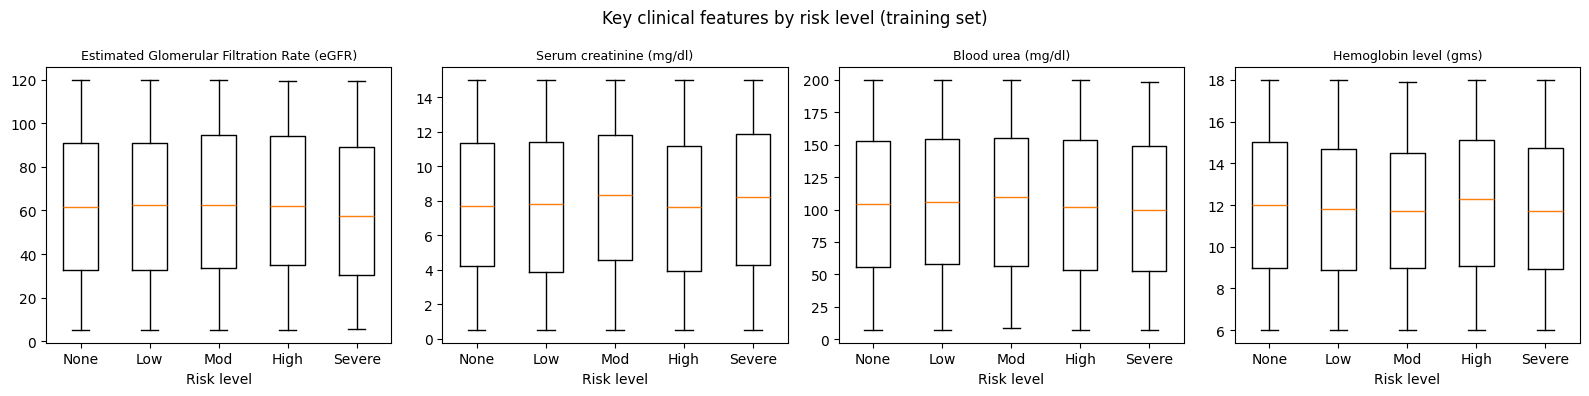

In [10]:
key = ["Estimated Glomerular Filtration Rate (eGFR)", "Serum creatinine (mg/dl)",
       "Blood urea (mg/dl)", "Hemoglobin level (gms)"]
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, key):
    ax.boxplot([train.loc[train["Target"] == c, col] for c in order], tick_labels=short, showfliers=False)
    ax.set_title(col, fontsize=9)
    ax.set_xlabel("Risk level")
fig.suptitle("Key clinical features by risk level (training set)")
fig.tight_layout()
plt.show()

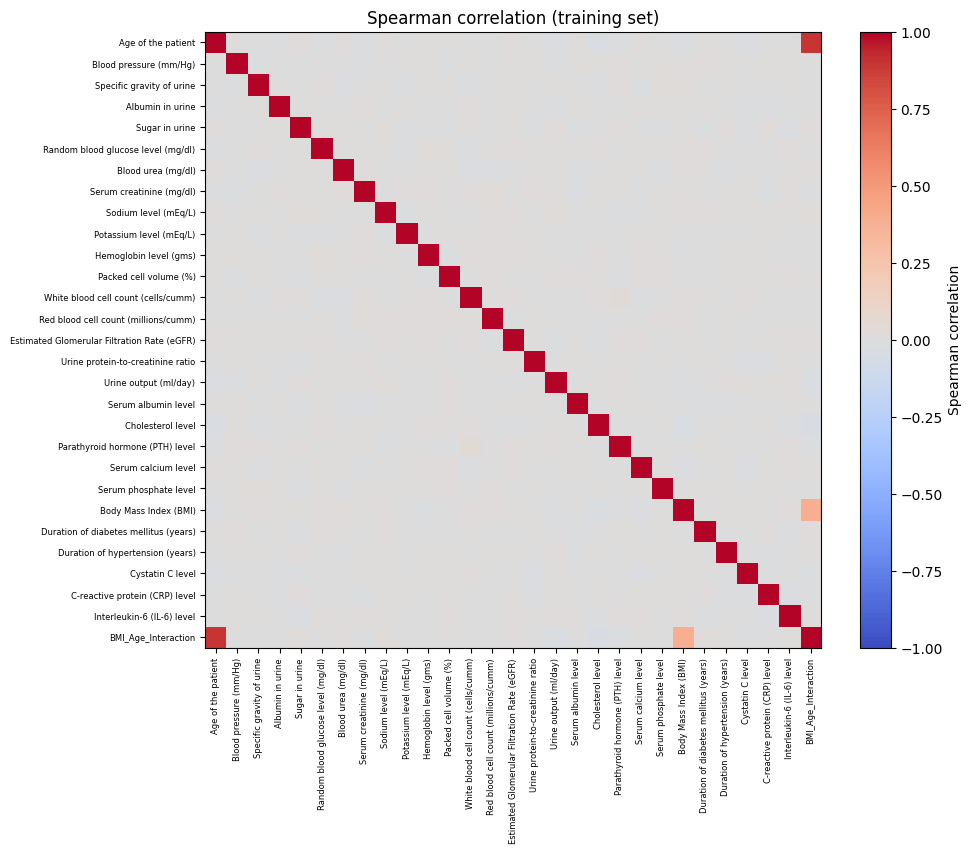

Largest correlation between two features: 0.894


In [11]:
corr = train[num_cols].corr(method="spearman")
plt.figure(figsize=(10, 8))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Spearman correlation")
plt.xticks(range(len(num_cols)), num_cols, rotation=90, fontsize=6)
plt.yticks(range(len(num_cols)), num_cols, fontsize=6)
plt.title("Spearman correlation (training set)")
plt.show()

off = corr.where(~np.eye(len(corr), dtype=bool)).abs()
print("Largest correlation between two features:", round(off.max().max(), 3))

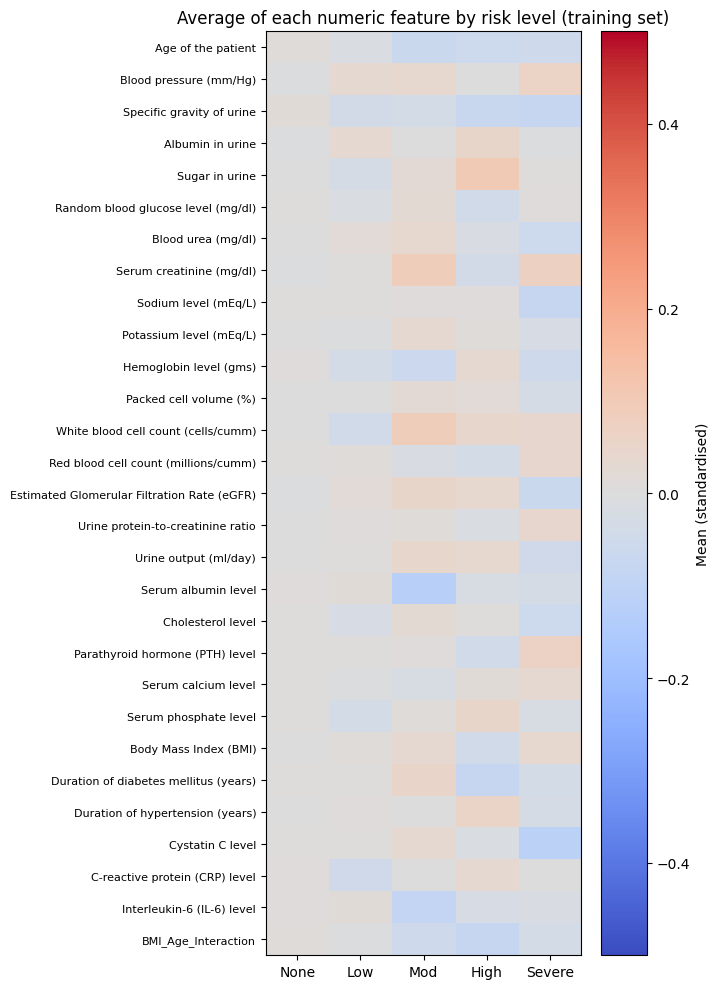

In [12]:
z = (train[num_cols] - train[num_cols].mean()) / train[num_cols].std()
means = z.groupby(train["Target"]).mean().reindex(order).T

fig, ax = plt.subplots(figsize=(7, 10))
im = ax.imshow(means, cmap="coolwarm", vmin=-0.5, vmax=0.5, aspect="auto")
ax.set_xticks(range(len(short)), short)
ax.set_yticks(range(len(num_cols)), num_cols, fontsize=8)
fig.colorbar(im, label="Mean (standardised)")
ax.set_title("Average of each numeric feature by risk level (training set)")
fig.tight_layout()
plt.show()

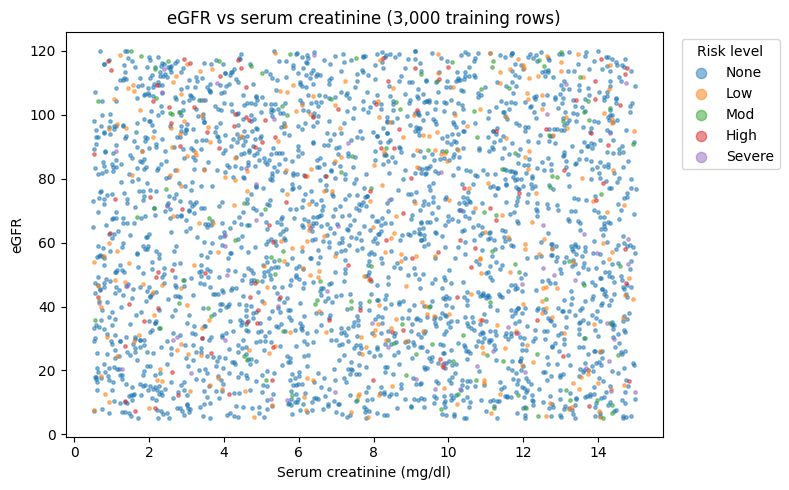

In [13]:
sample = train.sample(3000, random_state=RANDOM_STATE)

fig, ax = plt.subplots(figsize=(8, 5))
for c, s in zip(order, short):
    d = sample[sample["Target"] == c]
    ax.scatter(d["Serum creatinine (mg/dl)"], d["Estimated Glomerular Filtration Rate (eGFR)"], s=6, alpha=0.5, label=s)
ax.set_xlabel("Serum creatinine (mg/dl)")
ax.set_ylabel("eGFR")
ax.legend(title="Risk level", markerscale=3, bbox_to_anchor=(1.02, 1), loc="upper left")
ax.set_title("eGFR vs serum creatinine (3,000 training rows)")
fig.tight_layout()
plt.show()

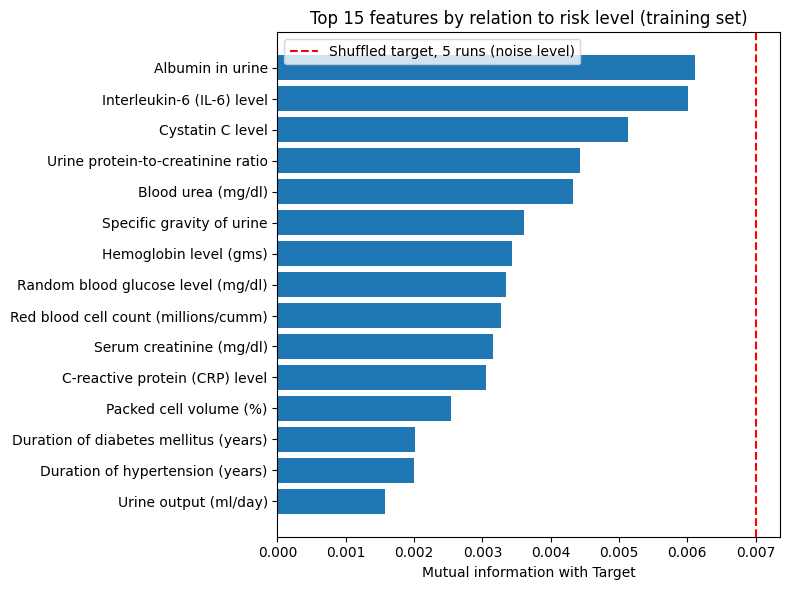

Engineered features: {'Diabetes_Hypertension_Interaction': 0.0, 'BMI_Age_Interaction': 0.0} noise: 0.007


In [14]:
is_cat = X_train.columns.isin(binary_cols)
mi = pd.Series(mutual_info_classif(X_train, y_train, discrete_features=is_cat, random_state=RANDOM_STATE), index=X_train.columns)
noise = max(
    mutual_info_classif(X_train, y_train.sample(frac=1, random_state=s).values, discrete_features=is_cat, random_state=RANDOM_STATE).max()
    for s in range(5)
)

top = mi.sort_values().tail(15)
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top.index, top.values)
ax.axvline(noise, color="red", linestyle="--", label="Shuffled target, 5 runs (noise level)")
ax.set_xlabel("Mutual information with Target")
ax.set_title("Top 15 features by relation to risk level (training set)")
ax.legend()
fig.tight_layout()
plt.show()
print("Engineered features:", mi[["Diabetes_Hypertension_Interaction", "BMI_Age_Interaction"]].round(4).to_dict(), "noise:", round(noise, 4))

**Observation:**
- Numeric skew close to 0 (BMI x Age 0.54), so no log transform needed
- Numeric distributions are flat, not bell-shaped
- 0/1 features split almost exactly 50/50 (physical activity 33/33/33; Diabetes x Hypertension 25%, as expected from two 50/50 features), unusual for real patients
- Original features barely correlated (largest 0.03); BMI x Age correlates with age (0.89), as it is built from it
- Feature averages almost equal across risk levels; no feature beats random noise, including the 2 engineered features (checked on training rows only)
- eGFR and creatinine unrelated, although eGFR is calculated from creatinine in real patients (KDIGO, 2024)

## 4. Check missing values, duplicates and outliers

In [15]:
q1 = train[num_cols].quantile(0.25)
q3 = train[num_cols].quantile(0.75)
iqr = q3 - q1
outliers = (train[num_cols] < q1 - 1.5 * iqr) | (train[num_cols] > q3 + 1.5 * iqr)
print("Outliers (IQR):", outliers.sum().sum())

Outliers (IQR): 7


**Observation:**
- No missing values or duplicates (section 1)
- 7 IQR outliers, all in BMI x Age; they are real combinations of high BMI and age, so they are kept

## 5. Scale

In [16]:
preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
], remainder="passthrough", verbose_feature_names_out=False).set_output(transform="pandas")

X_train_prep = preprocess.fit_transform(X_train)
X_test_prep = preprocess.transform(X_test)

target_map = {name: i for i, name in enumerate(order)}
y_train_enc = y_train.map(target_map)
y_test_enc = y_test.map(target_map)

print(X_train_prep.shape, X_test_prep.shape)
display(X_train_prep.head())

(16430, 46) (4108, 46)


,Age of the patient,Blood pressure (mm/Hg),Specific gravity of urine,Albumin in urine,Sugar in urine,Random blood glucose level (mg/dl),Blood urea (mg/dl),Serum creatinine (mg/dl),Sodium level (mEq/L),Potassium level (mEq/L),...,Appetite (good/poor),Pedal edema (yes/no),Anemia (yes/no),Family history of chronic kidney disease,Smoking status,Urinary sediment microscopy results,Physical activity level_high,Physical activity level_low,Physical activity level_moderate,Diabetes_Hypertension_Interaction
10980,-0.143503,-0.797128,-1.564794,1.475919,-0.875070,-0.021233,-0.954885,-1.336282,1.300319,-0.026660,...,0,0,0,1,1,1,0,0,1,0
12247,0.499407,-0.042023,-0.529822,1.475919,-1.463054,-0.229831,1.641260,0.882029,0.044167,0.778205,...,1,0,1,1,1,1,0,0,1,0
8236,1.423590,1.262249,-0.184831,0.299737,-1.463054,1.342677,0.124814,-0.418773,1.161188,-0.839449,...,1,1,0,1,1,0,0,1,0,1
4508,-0.063139,-0.350930,-0.529822,0.887828,-0.287085,1.206286,1.102780,-1.590214,1.584521,-1.699685,...,1,1,0,0,0,1,0,0,1,1
16176,-1.308777,1.056311,1.022636,0.299737,0.300899,0.099112,1.692662,0.776623,0.009261,1.239522,...,0,1,1,1,0,1,1,0,0,0


**Observation:**
- Numeric features scaled (mean 0, std 1) for kNN and the MLP; trees do not need it (Géron, 2022)
- 0/1 features, including physical activity and Diabetes x Hypertension, kept as they are
- Target encoded 0 to 4 in risk order
- Fitted on train only, then applied to test, so no leakage (Géron, 2022)

## 6. Class imbalance

In [17]:
weights = compute_class_weight("balanced", classes=np.arange(len(order)), y=y_train_enc)
display(pd.DataFrame({"Weight": weights.round(2)}, index=order))

,Weight
No_Disease,0.25
Low_Risk,2.00
Moderate_Risk,5.00
High_Risk,5.00
Severe_Disease,10.02


**Observation:**
- Severe gets weight 10, No Disease 0.25
- Stops models ignoring rare classes, which macro-F1 would punish

## 7. Save the processed data

In [18]:
out = Path("../../../../assets/datasets/2_KG_Kidney_Disease_Dataset/processed")
out.mkdir(exist_ok=True)

X_train_prep.assign(Target=y_train_enc).to_csv(out / "train.csv", index=False)
X_test_prep.assign(Target=y_test_enc).to_csv(out / "test.csv", index=False)

**Observation:**
- All model notebooks use these files, so every model sees the same data

**GenAI:** code generated with Claude (Anthropic) under the course GenAI policy (Framework statement 6), then evaluated by me.